# EDA — muestra analítica Centro v4

Este notebook utiliza exclusivamente las variables consolidadas `eda_*`. La muestra contiene departamentos con target observable y unidad comparable. No se aplican imputación, winsorización ni recortes permanentes.

In [7]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = sns.color_palette("colorblind")

def find_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del repositorio")

ROOT = find_root()
DATA = ROOT / "data/processed/zonaprop_v2_eda_centro_v4.csv.gz"
FLOW = ROOT / "reports/tables/flujo_muestra_eda_centro_v4.csv"
v4 = pd.read_csv(DATA, low_memory=False)
flow = pd.read_csv(FLOW)
print(f"Dataset: {DATA.name}")
print(f"Dimensiones: {v4.shape[0]:,} filas × {v4.shape[1]} columnas")

Dataset: zonaprop_v2_eda_centro_v4.csv.gz
Dimensiones: 9,498 filas × 122 columnas


## 1. Flujo e integridad

In [8]:
assert len(v4) == 9_498
assert v4.property_id.is_unique
assert v4.incluido_eda_v4.all()
assert not v4.auditoria_p0_pendiente.any()
assert not v4.auditoria_p1_pendiente.any()
assert v4.eda_precio_usd.notna().all()
assert v4.eda_precio_usd.gt(0).all()
display(flow)
print(f"Aptas para EDA espacial: {int(v4.apto_eda_espacial_v4.sum()):,} ({v4.apto_eda_espacial_v4.mean():.1%})")

,orden,etapa,observaciones,excluidas_en_etapa
0,1,universo_auditado_v3,9582,0
1,2,target_observable,9512,70
2,3,unidad_comparable_distrito_centro,9498,14
3,4,subconjunto_espacial_apto,8711,787


Aptas para EDA espacial: 8,711 (91.7%)


## 2. Faltantes en variables analíticas

,faltantes_pct
toilette,82.22
eda_cocheras,74.38
eda_expensas,71.96
orientacion,31.10
dormitorios,24.07
disposicion,23.92
eda_superficie_cubierta_m2,10.96
antiguedad_auditada,8.31
eda_banos,6.21
eda_superficie_total_m2,5.30


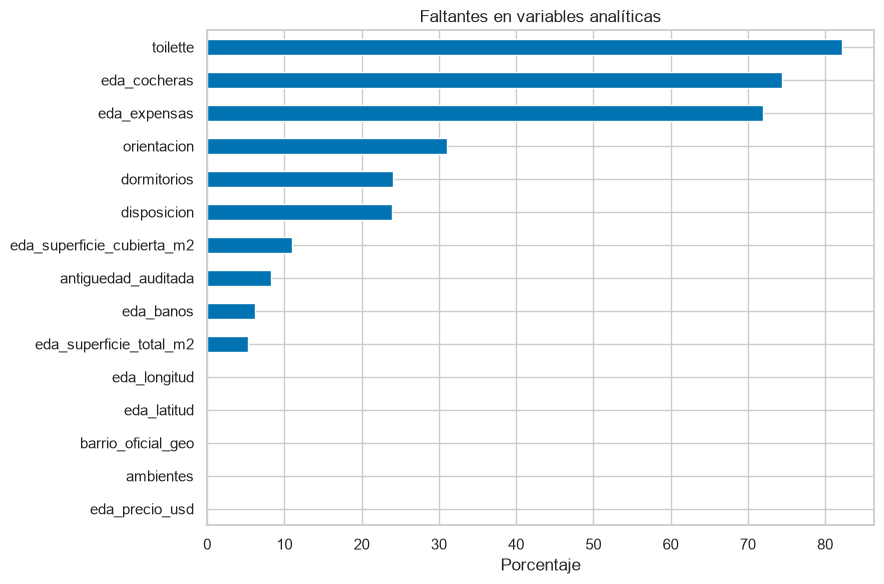

In [9]:
eda_cols = [
    "eda_precio_usd", "eda_superficie_total_m2", "eda_superficie_cubierta_m2",
    "ambientes", "dormitorios", "eda_banos", "eda_cocheras", "toilette",
    "antiguedad_auditada", "disposicion", "orientacion", "eda_expensas",
    "barrio_oficial_geo", "eda_latitud", "eda_longitud",
]
missing = (v4[eda_cols].isna().mean().mul(100).sort_values(ascending=False)
           .rename("faltantes_pct").to_frame())
display(missing.round(2))
ax = missing.sort_values("faltantes_pct").plot.barh(figsize=(9, 6), legend=False, color=PALETTE[0])
ax.set(title="Faltantes en variables analíticas", xlabel="Porcentaje", ylabel="")
plt.tight_layout()

## 3. Precio y precio por m²

Los límites p01–p99 se usan sólo para que el centro de la distribución resulte legible; ninguna fila se elimina del dataset.

,eda_precio_usd,eda_precio_m2
count,9498.00,8995.00
mean,159168.36,1791.01
std,118510.36,595.42
min,21600.00,166.67
1%,30000.00,681.82
25%,69000.00,1343.55
50%,128000.00,1760.00
75%,214800.00,2176.47
99%,546700.00,3519.00
max,1542000.00,5094.55


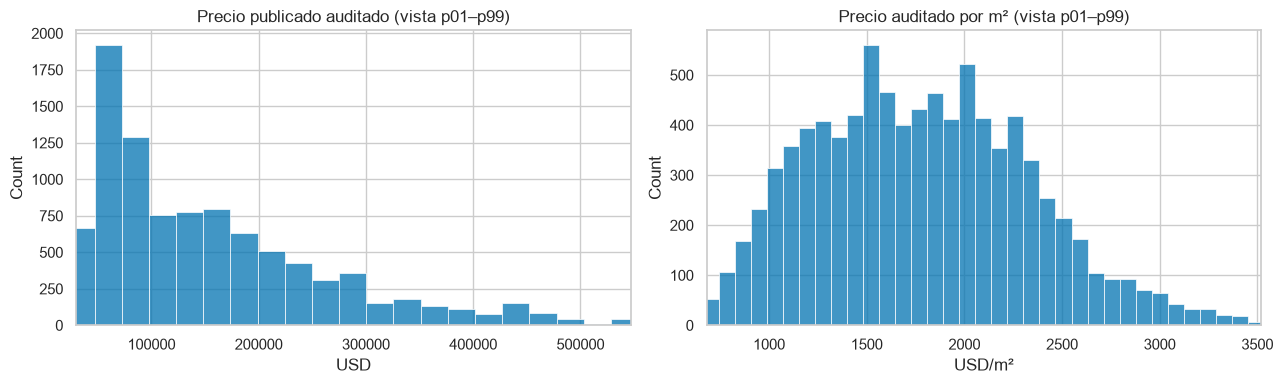

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in zip(axes, ["eda_precio_usd", "eda_precio_m2"], ["Precio publicado auditado", "Precio auditado por m²"]):
    values = pd.to_numeric(v4[col], errors="coerce").dropna()
    lo, hi = values.quantile([.01, .99])
    sns.histplot(values, bins=60, ax=ax, color=PALETTE[0])
    ax.set_xlim(lo, hi)
    ax.set_title(f"{title} (vista p01–p99)")
    ax.set_xlabel("USD" if col == "eda_precio_usd" else "USD/m²")
plt.tight_layout()
display(v4[["eda_precio_usd", "eda_precio_m2"]].describe(percentiles=[.01,.25,.5,.75,.99]).round(2))

## 4. Tipologías

n  precio_mediano  superficie_mediana  \
ambientes dormitorios                                             
3         2.0          2704        155000.0                79.0   
1         NaN          1784         56200.0                34.0   
4         3.0          1147        245721.0               121.0   
          2.0           812        145000.0                82.0   
2         1.0           632         65000.0                49.0   
5         3.0           626        260000.0               126.0   
3         1.0           318         75500.0                49.0   
6         3.0           206        252500.0               138.5   
3         NaN           195         94300.0                71.0   
4         NaN           165        103066.0               106.0   
5         2.0           163        155000.0                97.0   
1         1.0           101         66000.0                42.0   
2         NaN            86         62000.0                44.0   
5         4.0            85        335000.0               206.0   
7         3.0            57        290400.0               157.0   
6         4.0            49        345000.0               207.0   
5         NaN            41        170000.0               136.0   
4         1.0            41         84000.0                52.0   
7         4.0            37        330000.0               257.0   
8         4.0            31        350000.0               237.0   

                       precio_m2_mediano  
ambientes dormitorios                     
3         2.0                    1868.42  
1         NaN                    1645.16  
4         3.0                    2033.90  
          2.0                    1623.19  
2         1.0                    1602.63  
5         3.0                    1933.48  
3         1.0                    1550.00  
6         3.0                    1656.04  
3         NaN                    1700.00  
4         NaN                    1940.91  
5         2.0                    1666.67  
1         1.0                    1600.00  
2         NaN                    1346.15  
5         4.0                    1891.03  
7         3.0                    1627.14  
6         4.0                    1543.57  
5         NaN                    1601.43  
4         1.0                    1516.43  
7         4.0                    1318.64  
8         4.0                    1346.15

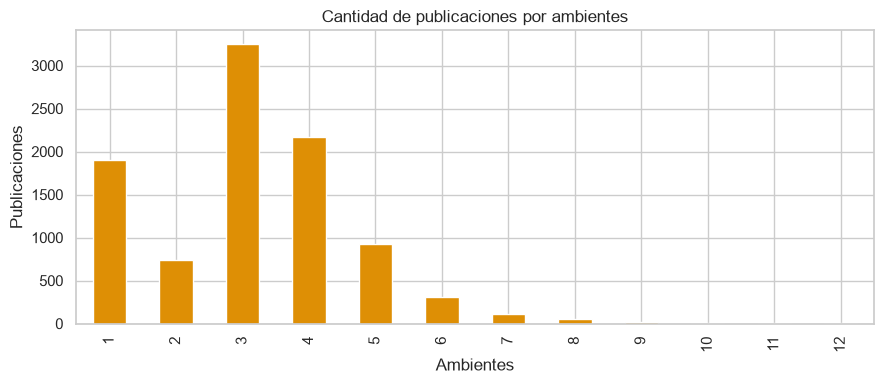

In [11]:
tipologias = (v4.groupby(["ambientes", "dormitorios"], dropna=False)
               .agg(n=("property_id", "size"), precio_mediano=("eda_precio_usd", "median"),
                    superficie_mediana=("eda_superficie_total_m2", "median"),
                    precio_m2_mediano=("eda_precio_m2", "median"))
               .sort_values("n", ascending=False))
display(tipologias.head(20).round(2))
ax = v4["ambientes"].value_counts().sort_index().plot.bar(figsize=(9,4), color=PALETTE[1])
ax.set(title="Cantidad de publicaciones por ambientes", xlabel="Ambientes", ylabel="Publicaciones")
plt.tight_layout()

## 5. Cobertura territorial

,n,precio_m2_mediano
barrio_oficial_geo,,
CENTRO,5183,1790.91
ALBERTO OLMEDO,862,1957.58
NTRA SRA DE LOURDES,740,1884.82
DEL ABASTO,590,1774.19
REPUBLICA DE LA 6TA,549,1444.44
ECHESORTU,428,1433.33
LUIS AGOTE,230,1423.08
ESPAÑA Y HOSPITALES,70,1000.00
JORGE CURA,23,1825.16


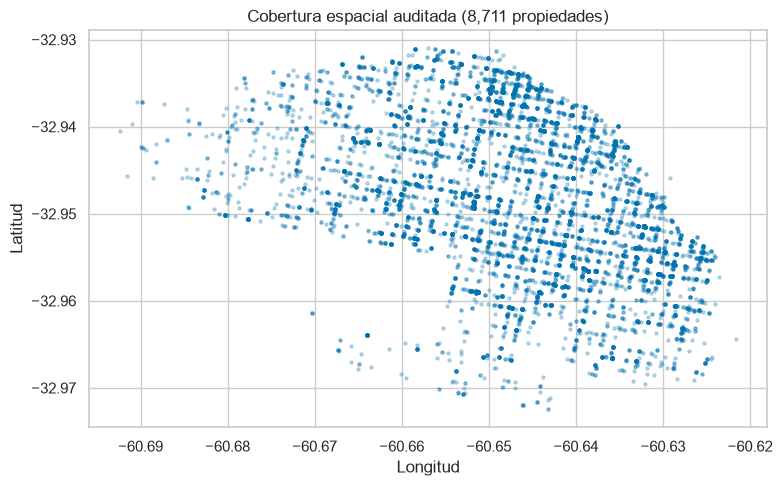

In [12]:
spatial = v4.loc[v4.apto_eda_espacial_v4].copy()
barrios = (spatial.groupby("barrio_oficial_geo", dropna=False)
           .agg(n=("property_id", "size"), precio_m2_mediano=("eda_precio_m2", "median"))
           .sort_values("n", ascending=False))
display(barrios.head(20).round(2))
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(spatial.eda_longitud, spatial.eda_latitud, s=5, alpha=.25, color=PALETTE[0])
ax.set(title=f"Cobertura espacial auditada ({len(spatial):,} propiedades)", xlabel="Longitud", ylabel="Latitud")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()

## Lectura

La v4 constituye la muestra de trabajo para la EDA: 9.498 unidades comparables, todas con target auditado. El subconjunto espacial contiene 8.711 observaciones; las 787 restantes deben conservarse para análisis no espaciales y para el escenario S1. Los faltantes siguen visibles y su tratamiento será específico por modelo dentro de cada fold.